# Fusión de caras con el AE entrenado

Este notebook es independiente de `overfitting.ipynb`. No entrena ningún modelo: carga el encoder y el decoder ya entrenados de `checkpoints/encoder_complex2.keras` y `checkpoints/decoder_complex2.keras`, codifica dos fotografías y realiza interpolaciones en el espacio latente.

Las imágenes de entrada deben estar disponibles en `data_test/edgar.jpg` y `data_test/guille.jpg` (se pueden cambiar en la celda de configuración).

## Dependencias

Si las dependencias ya están instaladas, basta con ejecutar las celdas de importación y siguientes.

In [1]:
import os

import cv2
import matplotlib.pyplot as plt
import numpy as np
from tensorflow import keras

In [6]:
IMG_SIZE = 64
CHECKPOINT_DIR = "checkpoints"
ENCODER_PATH = os.path.join(CHECKPOINT_DIR, "encoder_complex2.keras")
DECODER_PATH = os.path.join(CHECKPOINT_DIR, "decoder_complex2.keras")

FOTO_A = "data_test/edgar.jpg"
FOTO_B = "data_test/guille.jpg"

OUTPUT_INTERPOLATION = "fusion_ae_caras.png"
OUTPUT_WEIGHTS = "fusion_ae_pesos.png"

## Carga de los checkpoints

Se reutilizan los modelos guardados por `AE_complex2.ipynb`. Si faltan, el notebook falla explícitamente en lugar de entrenar un modelo distinto.

In [8]:
missing = [path for path in (ENCODER_PATH, DECODER_PATH) if not os.path.isfile(path)]
if missing:
    raise FileNotFoundError(
        "No se encontraron los checkpoints del AE_complex2: " + ", ".join(missing)
    )

encoder_ae = keras.models.load_model(ENCODER_PATH, compile=False)
decoder_ae = keras.models.load_model(DECODER_PATH, compile=False)
print(f"Encoder cargado: {ENCODER_PATH}")
print(f"Decoder cargado: {DECODER_PATH}")

Encoder cargado: checkpoints/encoder_complex2.keras
Decoder cargado: checkpoints/decoder_complex2.keras


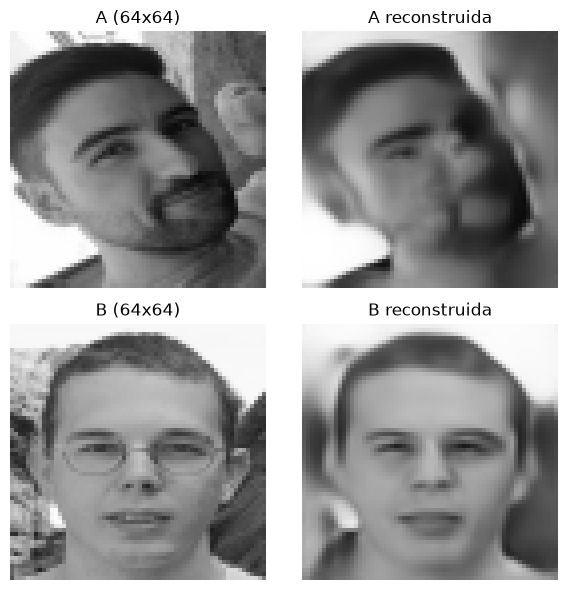

In [9]:
def load_face(path):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(f"No se encuentra la imagen: {path}")
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    return img.astype("float32")[..., None] / 255.0

face_a = load_face(FOTO_A)
face_b = load_face(FOTO_B)

# El encoder del AE determinista devuelve directamente el vector latente.
z_a = encoder_ae.predict(face_a[None], verbose=0)[0]
z_b = encoder_ae.predict(face_b[None], verbose=0)[0]

reconstruction_a = decoder_ae.predict(z_a[None], verbose=0)[0]
reconstruction_b = decoder_ae.predict(z_b[None], verbose=0)[0]

fig, axes = plt.subplots(2, 2, figsize=(6, 6))
for ax, image, title in zip(
    axes.flat,
    [face_a, reconstruction_a, face_b, reconstruction_b],
    ["A (64x64)", "A reconstruida", "B (64x64)", "B reconstruida"],
):
    ax.imshow(image[..., 0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Interpolación entre las dos caras

Se calcula `z(alpha) = (1 - alpha) z_A + alpha z_B` para nueve valores de `alpha` y se decodifica cada punto.

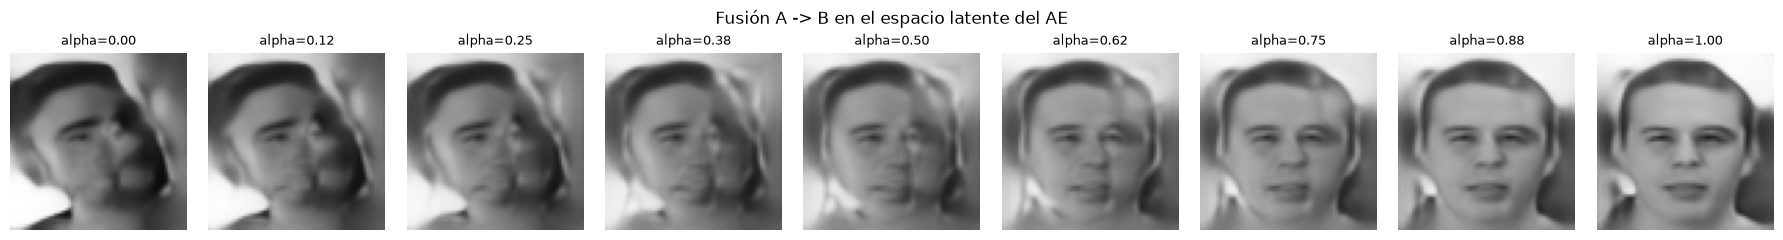

In [10]:
alphas = np.linspace(0, 1, 9)
z_interp = np.stack([(1 - alpha) * z_a + alpha * z_b for alpha in alphas]).astype(np.float32)
images_interp = decoder_ae.predict(z_interp, verbose=0)

fig, axes = plt.subplots(1, len(alphas), figsize=(2 * len(alphas), 2.4))
for ax, image, alpha in zip(axes, images_interp, alphas):
    ax.imshow(image[..., 0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"alpha={alpha:.2f}", fontsize=9)
    ax.axis("off")
fig.suptitle("Fusión A -> B en el espacio latente del AE", fontsize=12)
plt.tight_layout()
plt.savefig(OUTPUT_INTERPOLATION, dpi=200)
plt.show()

## Fusión con pesos distintos

Se generan mezclas con 25%, 50% y 75% de la cara B y se muestran junto a las imágenes originales.

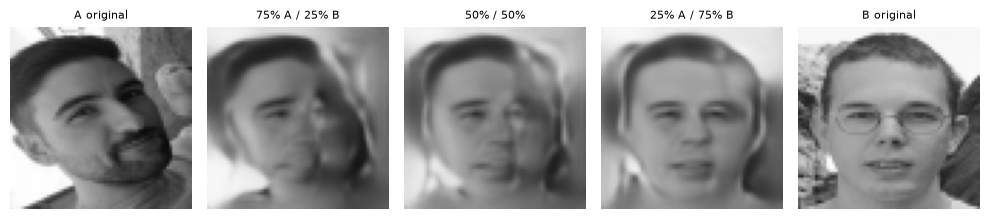

In [11]:
weights_b = [0.25, 0.5, 0.75]
z_mix = np.stack([(1 - weight) * z_a + weight * z_b for weight in weights_b]).astype(np.float32)
images_mix = decoder_ae.predict(z_mix, verbose=0)

all_images = [face_a] + list(images_mix) + [face_b]
titles = ["A original", "75% A / 25% B", "50% / 50%", "25% A / 75% B", "B original"]

fig, axes = plt.subplots(1, 5, figsize=(10, 2.4))
for ax, image, title in zip(axes, all_images, titles):
    ax.imshow(image[..., 0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(title, fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.savefig(OUTPUT_WEIGHTS, dpi=200)
plt.show()